In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
import keras

model_path = 'models/cnn_mnist_best.keras'
loaded_model = keras.models.load_model(model_path)
loaded_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
print("Збережену модель успішно завантажено та перекомпільовано!")


Збережену модель успішно завантажено та перекомпільовано!


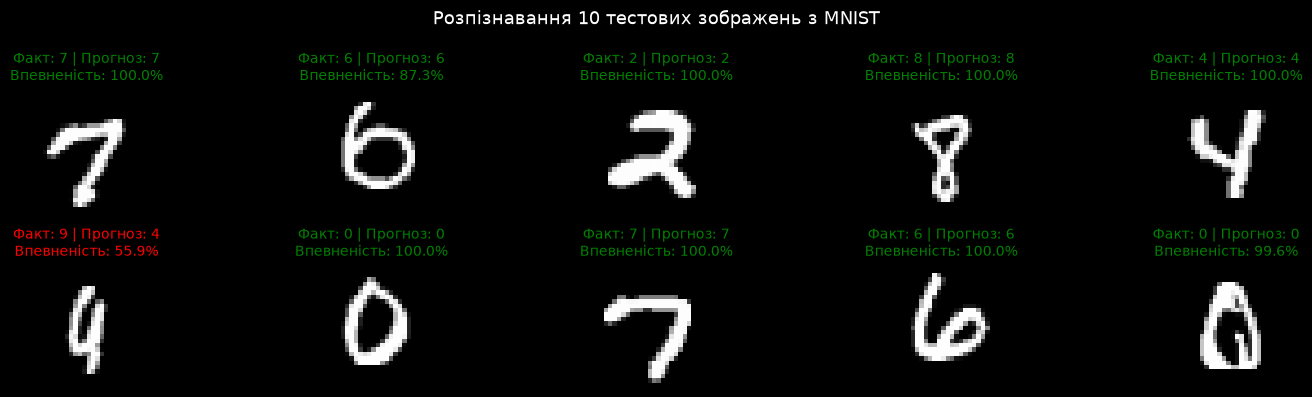

In [2]:
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = keras.datasets.mnist.load_data()
X_test_cnn = X_test_raw.reshape((-1, 28, 28, 1)).astype('float32') / 255.0

test_indices = np.random.choice(len(X_test_raw), 10, replace=False)
mnist_preds = loaded_model.predict(X_test_cnn[test_indices], verbose=0)
mnist_pred_labels = np.argmax(mnist_preds, axis=1)

plt.figure(figsize=(15, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test_raw[test_indices[i]], cmap='gray')
    conf = np.max(mnist_preds[i]) * 100
    is_correct = mnist_pred_labels[i] == y_test_raw[test_indices[i]]
    color = 'green' if is_correct else 'red'
    plt.title(f"Факт: {y_test_raw[test_indices[i]]} | Прогноз: {mnist_pred_labels[i]}\nВпевненість: {conf:.1f}%", color=color, fontsize=10)
    plt.axis('off')
plt.suptitle("Розпізнавання 10 тестових зображень з MNIST", fontsize=13)
plt.tight_layout()
plt.show()


In [3]:
def preprocess_custom_image(image_path):
    img = Image.open(image_path).convert('L')
    img_resized = img.resize((28, 28), Image.Resampling.LANCZOS)
    arr = np.array(img_resized, dtype=np.float32)

    arr_inverted = 255.0 - arr
    arr_normalized = arr_inverted / 255.0
    arr_normalized[arr_normalized < 0.15] = 0.0
    tensor_input = arr_normalized.reshape((1, 28, 28, 1))
    return img, arr_normalized, tensor_input


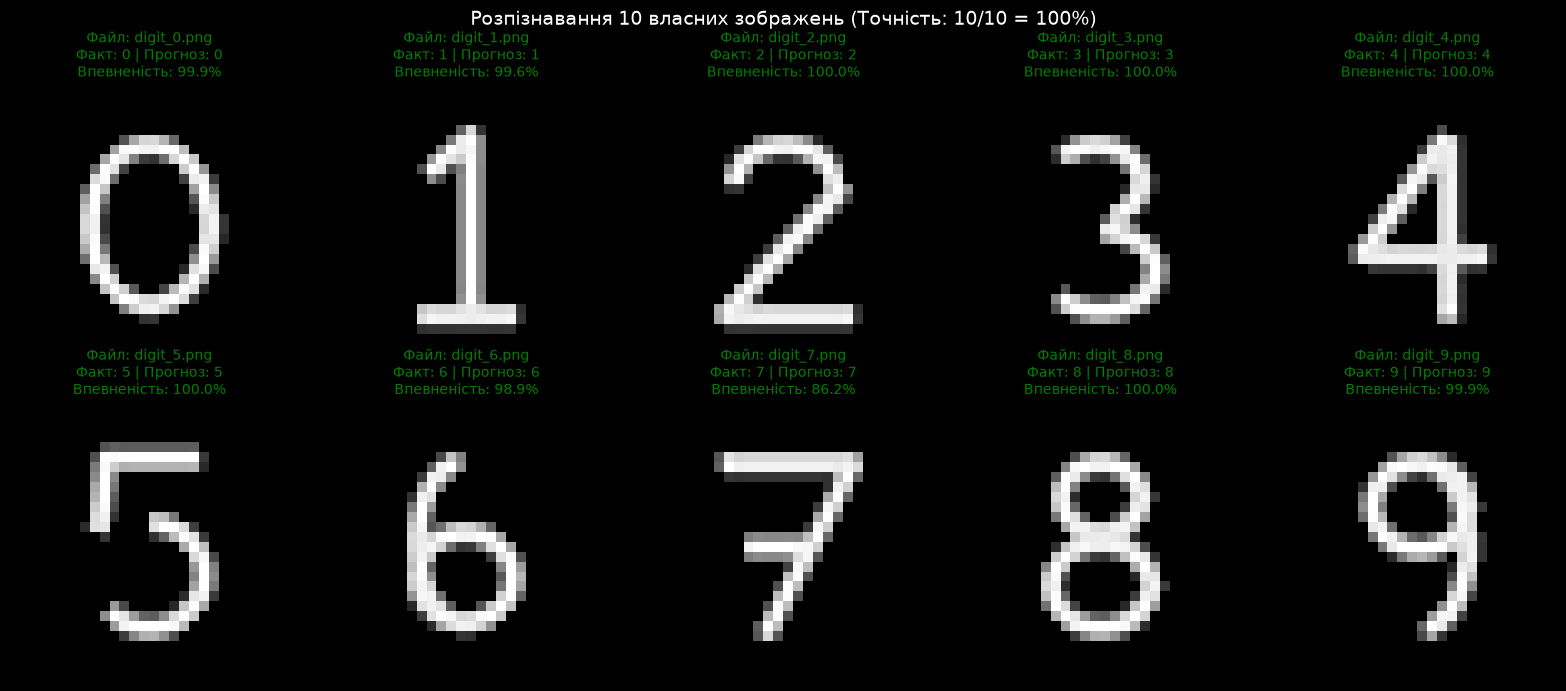

In [4]:
custom_images_dir = 'my_digits'
custom_files = sorted([f for f in os.listdir(custom_images_dir) if f.startswith('digit_') and f.endswith('.png')])

plt.figure(figsize=(16, 7))
correct_count = 0

for i, filename in enumerate(custom_files):
    true_digit = int(filename.split('_')[1].split('.')[0])
    img_path = os.path.join(custom_images_dir, filename)
    _, preprocessed_arr, tensor_input = preprocess_custom_image(img_path)
    
    pred_probs = loaded_model.predict(tensor_input, verbose=0)[0]
    pred_digit = np.argmax(pred_probs)
    conf = pred_probs[pred_digit] * 100
    
    if pred_digit == true_digit:
        correct_count += 1
        title_color = 'green'
    else:
        title_color = 'red'
        
    plt.subplot(2, 5, i + 1)
    plt.imshow(preprocessed_arr, cmap='gray')
    plt.title(f"Файл: {filename}\nФакт: {true_digit} | Прогноз: {pred_digit}\nВпевненість: {conf:.1f}%", color=title_color, fontsize=10)
    plt.axis('off')

plt.suptitle(f"Розпізнавання 10 власних зображень (Точність: {correct_count}/10 = {correct_count*10}%)", fontsize=14)
plt.tight_layout()
plt.show()


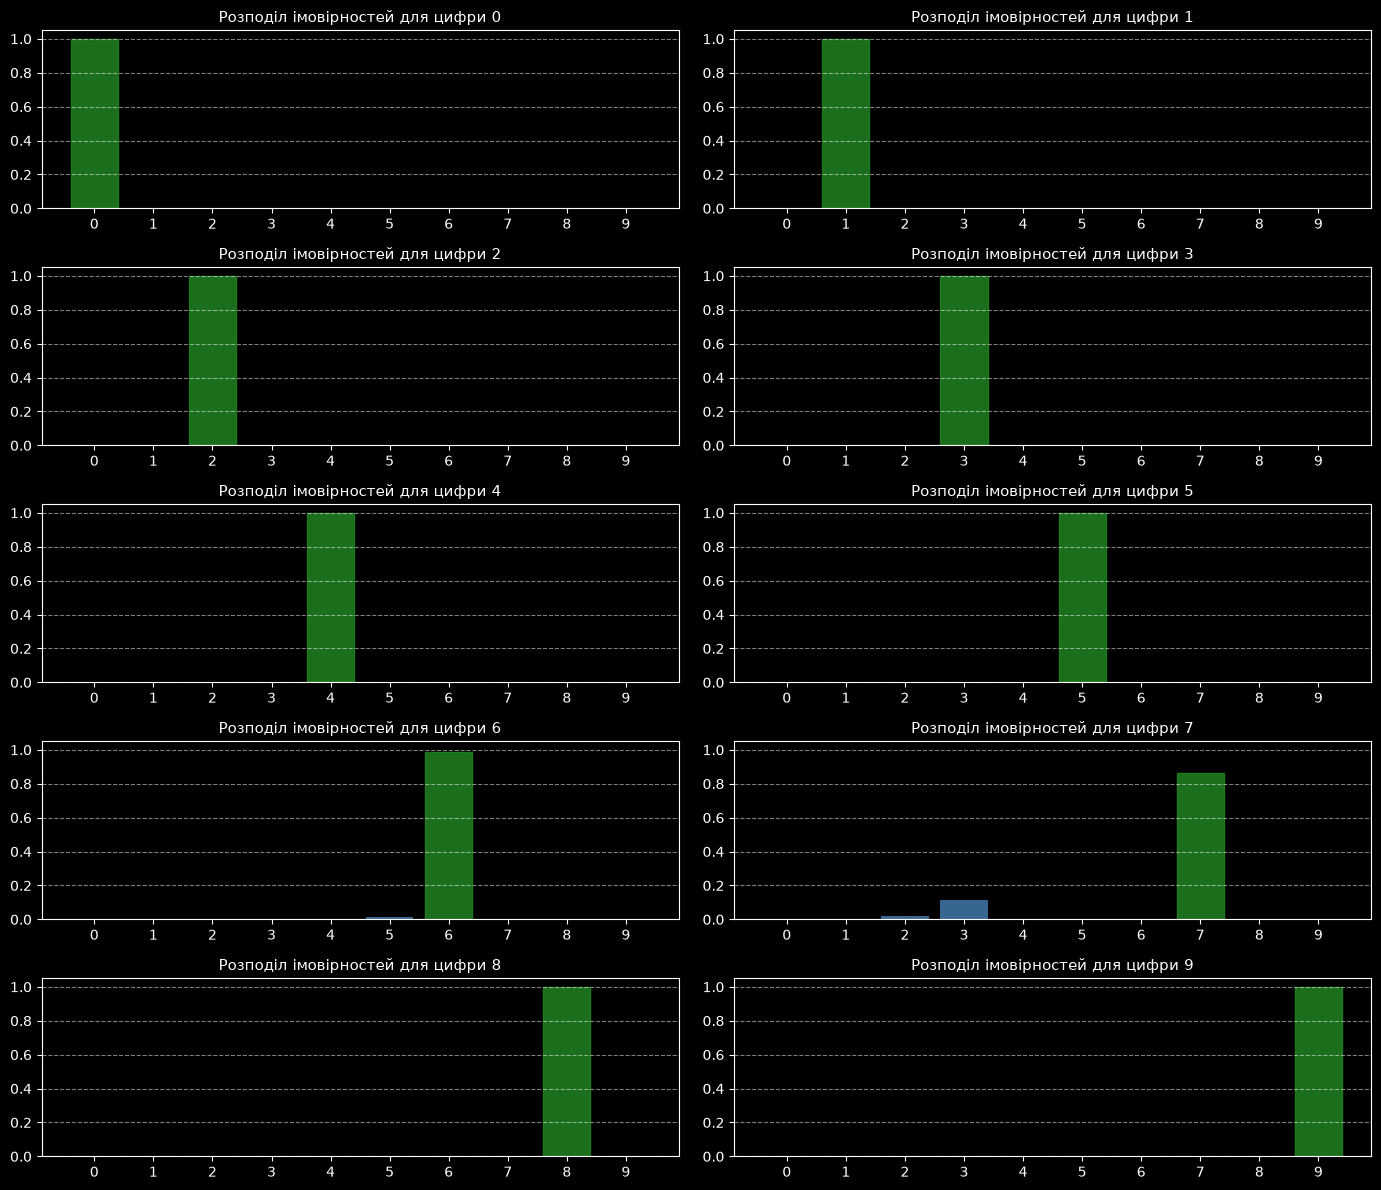

In [5]:
fig, axes = plt.subplots(5, 2, figsize=(14, 12))
axes = axes.flatten()

for i, filename in enumerate(custom_files):
    true_digit = int(filename.split('_')[1].split('.')[0])
    img_path = os.path.join(custom_images_dir, filename)
    _, _, tensor_input = preprocess_custom_image(img_path)
    pred_probs = loaded_model.predict(tensor_input, verbose=0)[0]
    
    bars = axes[i].bar(range(10), pred_probs, color='steelblue', alpha=0.8)
    bars[true_digit].set_color('forestgreen')
    if np.argmax(pred_probs) != true_digit:
        bars[np.argmax(pred_probs)].set_color('crimson')
        
    axes[i].set_title(f"Розподіл імовірностей для цифри {true_digit}", fontsize=11)
    axes[i].set_xticks(range(10))
    axes[i].set_ylim(0, 1.05)
    axes[i].grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [6]:
comparison_data = {
    "Модель": [
        "Базовий MLP (1 прихований шар 784)", 
        "1-шарова CNN (Conv2D + MaxPool)", 
        "Simple CNN (Conv 32, Dropout 0.2)", 
        "Deeper CNN (Conv 30+15, Dense 128+50)", 
        "Improved CNN (BatchNorm + Dropout)"
    ],
    "Кількість параметрів": [623290, 693962, 592074, 59933, 422154],
    "Тестова точність (%)": ["97.93%", "98.82%", "98.82%", "99.02%", "99.21%"],
    "Помилка класифікації (%)": ["2.07%", "1.18%", "1.18%", "0.98%", "0.79%"],
    "Цільове призначення": [
        "Базова лінія (Baseline)",
        "Швидка збіжність з Callback",
        "Проста згорткова топологія",
        "Багатошарова екстракція ознак",
        "Фінальна модель високої точності"
    ]
}

df_comparison = pd.DataFrame(comparison_data)
df_comparison


,Модель,Кількість параметрів,Тестова точність (%),Помилка класифікації (%),Цільове призначення
0,Базовий MLP (1 прихований шар 784),623290,97.93%,2.07%,Базова лінія (Baseline)
1,1-шарова CNN (Conv2D + MaxPool),693962,98.82%,1.18%,Швидка збіжність з Callback
2,"Simple CNN (Conv 32, Dropout 0.2)",592074,98.82%,1.18%,Проста згорткова топологія
3,"Deeper CNN (Conv 30+15, Dense 128+50)",59933,99.02%,0.98%,Багатошарова екстракція ознак
4,Improved CNN (BatchNorm + Dropout),422154,99.21%,0.79%,Фінальна модель високої точності
